In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression



In [2]:
def fetch_price_data(tickers, start_date, end_date):
    """
    Fetches adjusted close price data for two tickers from Yahoo Finance.
    Requires `yfinance` package: pip install yfinance
    """
    import yfinance as yf
    df = pd.DataFrame(yf.download(tickers, start=start_date, end=end_date)['Close'])

    df.dropna(inplace=True)
    return df



In [3]:
def check_coint(ticker1, ticker2, start_date, end_date):
  tickers = [ticker1, ticker2]
  df = fetch_price_data(tickers, start_date, end_date)
  df.dropna(inplace=True)
  X = df[f'{ticker1}'].values.reshape(-1, 1)
  y = df[f'{ticker2}'].values
  model = sm.OLS(y, sm.add_constant(X)).fit()
  df['Residuals'] = model.resid

  # Test stationarity (ADF test)
  adf_result = sm.tsa.adfuller(df['Residuals'])
  print(f"{ticker1} {ticker2} ADF Statistic: {adf_result[0]}")
  print(f"{ticker1} {ticker2} P-Value: {adf_result[1]}")



In [4]:
tickers = ['BTC-USD','ETH-USD','GC=F','USDJPY=X','EURUSD=X','TSLA','GOOGL','AAPL']
start_date = '2017-01-01'
end_date = '2018-12-31'
for i in range(len(tickers)):
  for j in range(i+1,len(tickers)):
    check_coint(tickers[i], tickers[j], start_date, end_date)

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  2 of 2 completed
[                       0%                       ]

BTC-USD ETH-USD ADF Statistic: -2.22587434602483
BTC-USD ETH-USD P-Value: 0.1969889273191045


[*********************100%***********************]  2 of 2 completed
[                       0%                       ]

BTC-USD GC=F ADF Statistic: -2.694715534894407
BTC-USD GC=F P-Value: 0.07495718488491031


...

USDJPY=X GOOGL ADF Statistic: -1.7384784009020096
USDJPY=X GOOGL P-Value: 0.4114041743902819
USDJPY=X AAPL ADF Statistic: -1.6939407846509194
USDJPY=X AAPL P-Value: 0.4342370399262372
EURUSD=X TSLA ADF Statistic: -3.6215407414444214
EURUSD=X TSLA P-Value: 0.005362319792008098


[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed


EURUSD=X GOOGL ADF Statistic: -1.6040295467932622
EURUSD=X GOOGL P-Value: 0.4815690036878769
EURUSD=X AAPL ADF Statistic: -1.6077806288598164
EURUSD=X AAPL P-Value: 0.47968396397814134
TSLA GOOGL ADF Statistic: -1.5893595032104317
TSLA GOOGL P-Value: 0.4889363687802485


[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed


TSLA AAPL ADF Statistic: -1.8074381773286394
TSLA AAPL P-Value: 0.376775148249426
GOOGL AAPL ADF Statistic: -2.487183324295347
GOOGL AAPL P-Value: 0.1186239851906506


In [5]:
def compute_log_spread(df, ticker1, ticker2):
    """
    Computes the log‐price spread: ln(P1) - ln(P2).
    """
    return np.log(df[ticker1]) - np.log(df[ticker2])



In [6]:
def find_kagi_turning_points(spread, H):
    """
    Identifies turning points in the spread series using a Kagi‐style threshold H.
    Returns a list of (timestamp, spread_value).
    """
    turn_points = []
    last_extreme = spread.iloc[0]
    direction = 0  # 1 = uptrend, -1 = downtrend

    for timestamp, value in spread.items():
        if direction >= 0 and value < last_extreme - H:
            # switch to downtrend
            turn_points.append((timestamp, last_extreme))
            direction = -1
            last_extreme = value
        elif direction <= 0 and value > last_extreme + H:
            # switch to uptrend
            turn_points.append((timestamp, last_extreme))
            direction = 1
            last_extreme = value
        else:
            # update the current extreme
            if direction >= 0:
                last_extreme = max(last_extreme, value)
            else:
                last_extreme = min(last_extreme, value)

    # append the final turning point
    turn_points.append((spread.index[-1], last_extreme))
    return turn_points



In [7]:
def backtest_contrarian_H_strategy(turn_points):
    """
    Backtests the contrarian H‐strategy:
    At each turning point, short the spread (i.e., short asset1, long asset2),
    and close at the next turning point.
    Returns a pandas Series of per‐trade P&L indexed by exit timestamp.
    """
    pnl = []
    dates = []
    for i in range(len(turn_points) - 1):
        t0, s0 = turn_points[i]
        t1, s1 = turn_points[i + 1]
        pnl.append(-(s1 - s0))
        dates.append(t1)
    return pd.Series(pnl, index=dates)



In [ ]:
def run_backtest(ticker1, ticker2, start_date, end_date):
    """
    Executes the full backtest pipeline and plots results.
    Returns a dictionary of performance metrics.
    """
    # 1. Fetch data
    tickers = [ticker1, ticker2]
    df = fetch_price_data(tickers, start_date, end_date)

    # 2. Compute spread and threshold H
    spread = compute_log_spread(df, ticker1, ticker2)
    H = spread.std()

    # 3. Identify turning points
    turn_points = find_kagi_turning_points(spread, H)

    # 4. Backtest strategy
    pnl_series = backtest_contrarian_H_strategy(turn_points)
    cum_pnl = pnl_series.cumsum()

    # 5. Performance metrics
    total_pnl = cum_pnl.iloc[-1]
    num_trades = len(pnl_series)
    avg_pnl = pnl_series.mean()
    std_pnl = pnl_series.std()
    sharpe_per_trade = (avg_pnl / std_pnl * np.sqrt(num_trades)) if std_pnl != 0 else np.nan

    # 6. Plot cumulative P&L
    plt.figure(figsize=(10, 5))
    plt.plot(cum_pnl, label='Cumulative P&L')
    plt.title(f'Contrarian H-Strategy: {ticker1} vs {ticker2}')
    plt.xlabel('Date')
    plt.ylabel('Cumulative P&L')
    plt.grid(True)
    plt.legend()
    plt.show()

    # 7. Return summary
    return {
        'Total P&L': total_pnl,
        'Number of Trades': num_trades,
        'Average P&L per Trade': avg_pnl,
        'Std Dev of P&L': std_pnl,
        'Sharpe (per-trade)': sharpe_per_trade
    }



[*********************100%***********************]  2 of 2 completed


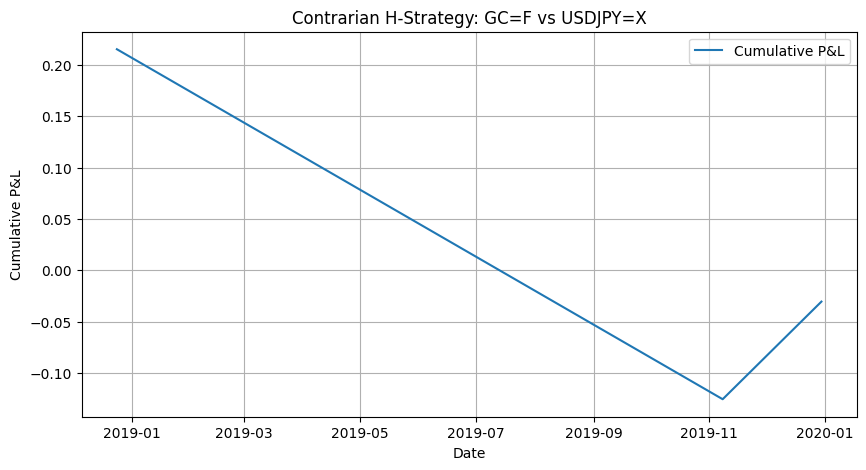

{'Total P&L': np.float64(-0.030535672078692677), 'Number of Trades': 3, 'Average P&L per Trade': np.float64(-0.010178557359564225), 'Std Dev of P&L': 0.29254516144786863, 'Sharpe (per-trade)': np.float64(-0.060263442428053864)}


In [ ]:
# Example usage (uncomment to run):
ticker1 = 'GC=F'
ticker2 = 'USDJPY=X'
start_date = '2018-01-01'
end_date = '2019-12-31'
performance = run_backtest(ticker1, ticker2, start_date,end_date)
print(performance)

[*********************100%***********************]  2 of 2 completed


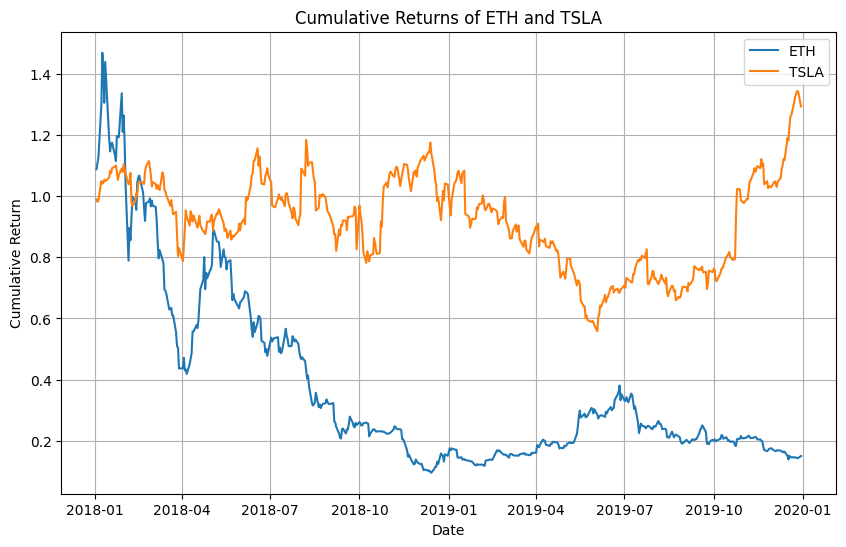

In [ ]:
# prompt: plot ETH and TSLA cummulative return

import matplotlib.pyplot as plt
# Assuming 'df' is your DataFrame with 'ETH-USD' and 'TSLA' prices.
# Replace this with your actual data loading and preprocessing.


def plot_cumulative_returns(df):
    """Plots the cumulative returns of ETH and TSLA."""

    # Calculate daily returns
    daily_returns = df[['ETH-USD', 'TSLA']].pct_change()

    # Calculate cumulative returns
    cumulative_returns = (1 + daily_returns).cumprod()

    # Plot the cumulative returns
    plt.figure(figsize=(10, 6))
    plt.plot(cumulative_returns['ETH-USD'], label='ETH')
    plt.plot(cumulative_returns['TSLA'], label='TSLA')
    plt.title('Cumulative Returns of ETH and TSLA')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage assuming you have a DataFrame named 'df' with 'ETH-USD' and 'TSLA' columns
# Replace with your actual DataFrame
#plot_cumulative_returns(df)
tickers = ['ETH-USD', 'TSLA']
start_date = '2018-01-01'
end_date = '2019-12-31'
df = fetch_price_data(tickers, start_date, end_date)
plot_cumulative_returns(df)


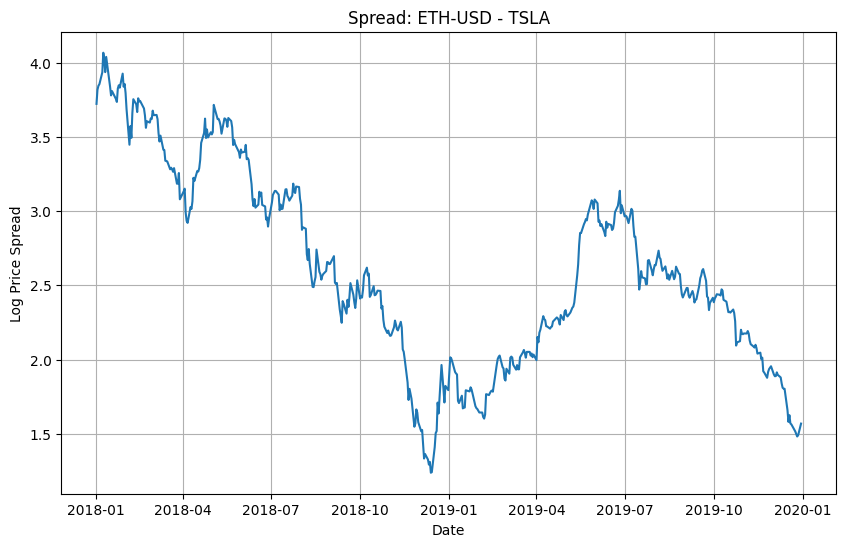

In [ ]:
# prompt: plot ETH and TSLA log spread

import matplotlib.pyplot as plt
# Assuming 'df' is your DataFrame with 'ETH-USD' and 'TSLA' prices.
# Replace this with your actual data loading and preprocessing.

def plot_log_spread(df, ticker1, ticker2):
    """Plots the log spread of two assets."""
    spread = compute_log_spread(df, ticker1, ticker2)
    plt.figure(figsize=(10, 6))
    plt.plot(spread)
    plt.title(f'Log Spread: {ticker1} vs {ticker2}')
    plt.xlabel('Date')
    plt.ylabel('Log Spread')
    plt.grid(True)
    plt.show()

# Example usage assuming you have a DataFrame named 'df' with 'ETH-USD' and 'TSLA' columns
# Replace with your actual DataFrame
plot_log_spread(df, 'ETH-USD', 'TSLA')
